# Dữ liệu và EDA cho bài toán phân loại CKD

Người 1 phụ trách bước 1, 3, 4, 5: xác định bài toán, kiểm tra dữ liệu, làm sạch định dạng và EDA.
Đầu vào là 24 thuộc tính; `id` chỉ là định danh, `classification` là nhãn và không được đưa vào X.
Đầu ra của mô hình sau này là CKD (1) hoặc Not CKD (0); xác suất do người 2 và 3 bổ sung.
Người dùng dự kiến là nhóm sinh viên và giảng viên khi học, kiểm tra và demo; không dùng để chẩn đoán.
Lớp dương là CKD; ưu tiên Recall = TP/(TP+FN), theo dõi thêm Precision, F1 và ROC-AUC.

Nguồn mô tả gốc: [UCI Chronic Kidney Disease](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease), DOI 10.24432/C5G020.
Bản CSV đang dùng có 400 dòng, 24 thuộc tính, một cột nhãn và thêm `id`.
Chưa có lịch sử tải để xác nhận URL trực tiếp của bản CSV này; không coi kích thước giống nhau là bằng chứng trùng toàn bộ dữ liệu.
Xem `data/README.md` và `reports/data_dictionary.md` để biết nguồn, dấu kiểm tệp và ý nghĩa cột.

Chạy **Restart Kernel and Run All** theo thứ tự. Các kết quả EDA là mô tả trên toàn bộ dữ liệu;
không dùng để chốt đặc trưng, ngưỡng, imputer hoặc mô hình. Người 2 phải chia train/test trước khi fit bất kỳ bước học tham số nào.


In [1]:
import sys
from pathlib import Path
import pandas as pd

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root))
from src.config import RAW_DATA_PATH, TABLES_DIR, FIGURES_DIR, TARGET, NUMERIC_COLUMNS, CODED_COLUMNS
from src.preprocess import clean_raw

raw = pd.read_csv(RAW_DATA_PATH)
df = clean_raw(raw)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
print("Dữ liệu gốc:", raw.shape, "Sau làm sạch:", df.shape)
print("Số dòng trùng sau bỏ id:", df.duplicated().sum())
print("Nhãn thiếu:", df[TARGET].isna().sum())
print("Số dòng đầy đủ:", len(df.dropna()))
display(raw.head())
raw.info()
display(df.head())
profile = pd.DataFrame({
    "raw_dtype": raw.dtypes.astype(str).reindex(df.columns),
    "clean_dtype": df.dtypes.astype(str),
    "missing_before": raw.isna().sum().reindex(df.columns),
    "missing_after": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_non_missing": df.nunique(),
})
display(profile)
profile.to_csv(TABLES_DIR / "data_quality.csv", encoding="utf-8-sig", index_label="column")
# Các cột mã hóa sg/al/su có mô tả riêng; dtype số không tự động có nghĩa là liên tục.
summary = df[list(NUMERIC_COLUMNS)].describe().T
display(summary.round(2))
summary.to_csv(TABLES_DIR / "numeric_summary.csv", encoding="utf-8-sig", index_label="column")
category_summary = df[["sg", "al", "su", "rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]].astype("string").describe().T
display(category_summary)
category_summary.to_csv(TABLES_DIR / "categorical_summary.csv", encoding="utf-8-sig", index_label="column")


Dữ liệu gốc: (400, 26) Sau làm sạch: (400, 25)
Số dòng trùng sau bỏ id: 0
Nhãn thiếu: 0
Số dòng đầy đủ: 158


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    str    
 7   pc              335 non-null    str    
 8   pcc             396 non-null    str    
 9   ba              396 non-null    str    
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    str    
 17  wc              295 non-null    str    
 18  r

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,1
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,1
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,1
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,1
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,1


,raw_dtype,clean_dtype,missing_before,missing_after,missing_percent,unique_non_missing
age,float64,float64,9,9,2.25,76
bp,float64,float64,12,12,3.00,10
sg,float64,float64,47,47,11.75,5
al,float64,float64,46,46,11.50,6
su,float64,float64,49,49,12.25,6
rbc,str,object,152,152,38.00,2
pc,str,object,65,65,16.25,2
pcc,str,object,4,4,1.00,2
ba,str,object,4,4,1.00,2
bgr,float64,float64,44,44,11.00,146


,count,mean,std,min,25%,50%,75%,max
age,391.0,51.48,17.17,2.0,42.0,55.00,64.5,90.0
bp,388.0,76.47,13.68,50.0,70.0,80.00,80.0,180.0
bgr,356.0,148.04,79.28,22.0,99.0,121.00,163.0,490.0
bu,381.0,57.43,50.50,1.5,27.0,42.00,66.0,391.0
sc,383.0,3.07,5.74,0.4,0.9,1.30,2.8,76.0
sod,313.0,137.53,10.41,4.5,135.0,138.00,142.0,163.0
pot,312.0,4.63,3.19,2.5,3.8,4.40,4.9,47.0
hemo,348.0,12.53,2.91,3.1,10.3,12.65,15.0,17.8
pcv,329.0,38.88,8.99,9.0,32.0,40.00,45.0,54.0
wc,294.0,8406.12,2944.47,2200.0,6500.0,8000.00,9800.0,26400.0


,count,unique,top,freq
sg,353,5,1.02,106
al,354,6,0.0,199
su,351,6,0.0,290
rbc,248,2,normal,201
pc,335,2,normal,259
pcc,396,2,notpresent,354
ba,396,2,notpresent,374
htn,398,2,no,251
dm,398,2,no,261
cad,398,2,no,364


### Kiểm tra sau làm sạch

Giữ nguyên 400 dòng; bỏ `id` còn 25 cột gồm 24 thuộc tính và nhãn. Không có dòng trùng và không thiếu nhãn.
Ba ô `\t?` ở `pcv`, `wc`, `rc` được chuyển thành thiếu thực sự, mỗi cột tăng một ô thiếu.
Đây là sửa định dạng, không phải tạo dữ liệu mới. Chỉ còn 158 dòng đầy đủ; bỏ mọi dòng thiếu sẽ mất 242/400 dòng (60,5%), nên giữ thiếu để người 2 xử lý bằng imputer fit trên train.


In [2]:

import pandas as pd
import sys
from pathlib import Path

# Xác định thư mục dự án
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

sys.path.insert(0, str(root))

from src.preprocess import clean_raw

# Đọc và làm sạch dữ liệu
df = pd.read_csv(root / "data/raw/kidney_disease.csv")
df = clean_raw(df)

# Đếm số lượng từng lớp
counts = df["classification"].value_counts()
print(counts)

# Tính tỷ lệ phần trăm
percentages = df["classification"].value_counts(normalize=True) * 100
print("\nTỷ lệ phần trăm:")
print(percentages.round(2))


classification
1    250
0    150
Name: count, dtype: int64



Tỷ lệ phần trăm:
classification
1    62.5
0    37.5
Name: proportion, dtype: float64


In [3]:

# Đếm số giá trị thiếu của từng cột
missing_count = df.isna().sum()

# Tính tỷ lệ thiếu (%)
missing_percent = (
    missing_count / len(df) * 100
)

# Tạo bảng thống kê
missing_table = pd.DataFrame({
    "So_luong_thieu": missing_count,
    "Ty_le_thieu_%": missing_percent
})

# Sắp xếp từ thiếu nhiều đến ít
missing_table = missing_table.sort_values(
    "So_luong_thieu", ascending=False
)

# Chỉ hiển thị các cột có dữ liệu thiếu
display(missing_table[
    missing_table["So_luong_thieu"] > 0
])

missing_table.to_csv(TABLES_DIR / "missing_values.csv", encoding="utf-8-sig", index_label="column")


,So_luong_thieu,Ty_le_thieu_%
rbc,152,38.00
rc,131,32.75
wc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


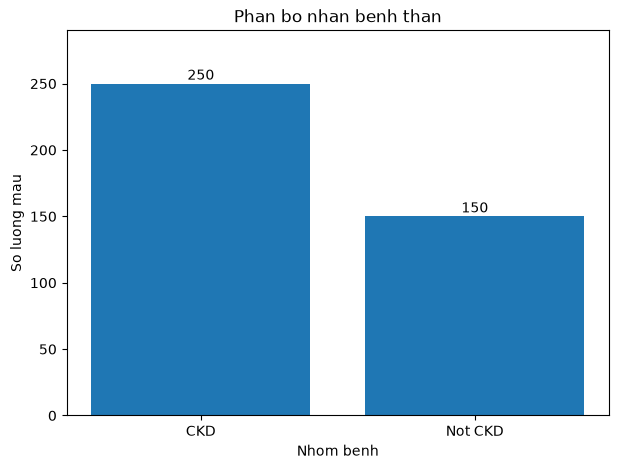

In [4]:

import matplotlib.pyplot as plt

# Số lượng từng nhóm
labels = ["CKD", "Not CKD"]
values = [int((df[TARGET] == 1).sum()), int((df[TARGET] == 0).sum())]

# Tạo biểu đồ
plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.title("Phan bo nhan benh than")
plt.xlabel("Nhom benh")
plt.ylabel("So luong mau")

# Hiển thị số lượng trên cột
for i, value in enumerate(values):
    plt.text(i, value + 3, str(value), ha="center")

plt.ylim(0, max(values) * 1.16)

# Lưu biểu đồ
folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)
plt.savefig(folder / "class_distribution.png")

plt.show()


### Nhận xét phân bố lớp

CKD có 250 mẫu (62,5%), Not CKD có 150 mẫu (37,5%), tỷ lệ khoảng 1,67:1.
Luôn đoán CKD đã đạt Accuracy 62,5% và Recall CKD 100%, nhưng Precision chỉ 62,5% và không phân biệt được hai nhóm.
Vì vậy Recall phải được đọc cùng Precision, F1, ROC-AUC và baseline; cần chia dữ liệu có phân tầng.


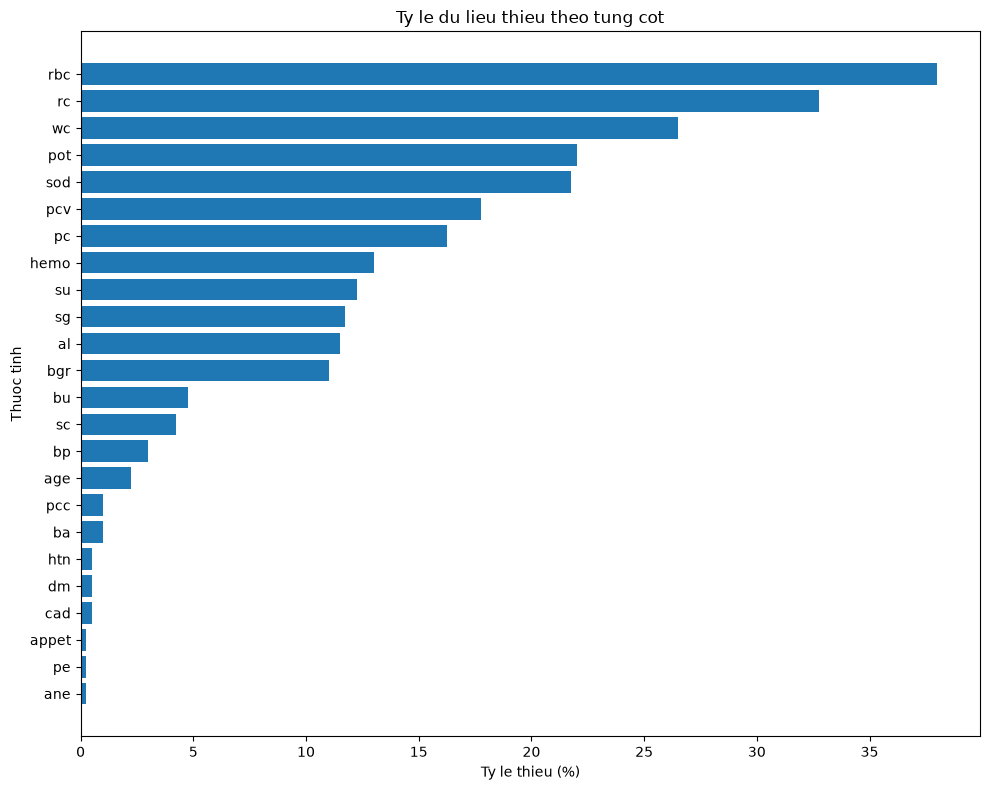

In [5]:

import matplotlib.pyplot as plt

# Chỉ lấy cột có dữ liệu thiếu
missing_plot = missing_table[
    missing_table["So_luong_thieu"] > 0
]

plt.figure(figsize=(10, 8))

plt.barh(
    missing_plot.index[::-1],
    missing_plot["Ty_le_thieu_%"][::-1]
)

plt.title("Ty le du lieu thieu theo tung cot")
plt.xlabel("Ty le thieu (%)")
plt.ylabel("Thuoc tinh")

plt.tight_layout()

# Lưu biểu đồ
folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét dữ liệu thiếu

`rbc` thiếu nhiều nhất: 152/400 (38%), tiếp theo `rc` 32,75%, `wc` 26,5%, `pot` 22% và `sod` 21,75%.
Không có nhãn thiếu. Biểu đồ phản ánh tỷ lệ thiếu toàn tập, chưa cho biết cơ chế thiếu.
Không tự loại cột chỉ vì thiếu nhiều; người 2 đánh giá cách xử lý bằng CV trên train. Không điền trung bình hoặc mode trên toàn tập trước khi chia dữ liệu.


In [6]:

# Thống kê thuộc tính tuổi
print("THONG KE TUOI BENH NHAN")
print(df["age"].describe())

print("\nSo gia tri tuoi bi thieu:")
print(df["age"].isna().sum())


THONG KE TUOI BENH NHAN
count    391.000000
mean      51.483376
std       17.169714
min        2.000000
25%       42.000000
50%       55.000000
75%       64.500000
max       90.000000
Name: age, dtype: float64

So gia tri tuoi bi thieu:
9


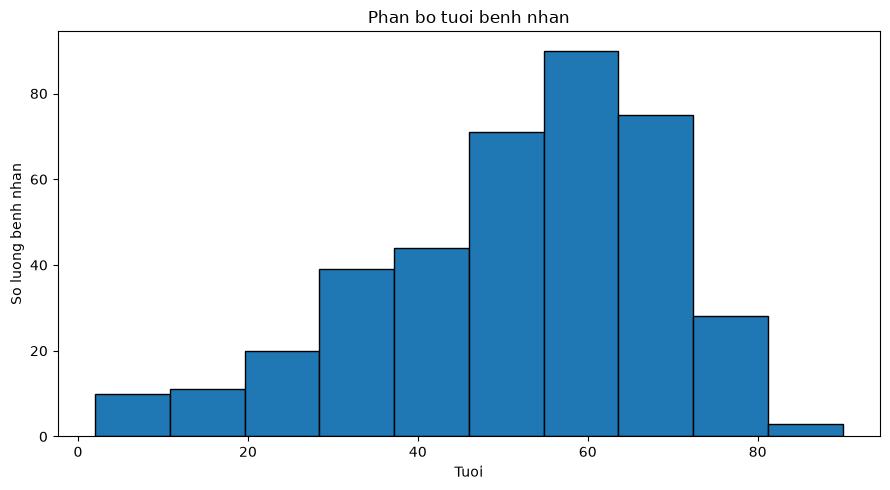

In [7]:

import matplotlib.pyplot as plt

# Lấy dữ liệu tuổi, bỏ qua ô thiếu khi vẽ
age_data = df["age"].dropna()

# Tạo biểu đồ
plt.figure(figsize=(9, 5))

plt.hist(
    age_data,
    bins=10,
    edgecolor="black"
)

plt.title("Phan bo tuoi benh nhan")
plt.xlabel("Tuoi")
plt.ylabel("So luong benh nhan")

plt.tight_layout()

# Lưu biểu đồ
folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét phân bố tuổi

Có 391 giá trị tuổi, thiếu 9 (2,25%); tuổi từ 2 đến 90, trung bình 51,48 và trung vị 55.
Dữ liệu gồm cả trẻ em và người lớn, nên không mô tả mẫu như chỉ gồm người trưởng thành.
Sự phân bố của mẫu này không đại diện tự động cho dân số.


In [8]:

# Thống kê tuổi theo từng nhóm bệnh
age_stats = df.groupby("classification")["age"].agg([
    "count", "mean", "median", "min", "max"
])

print("THONG KE TUOI THEO NHOM BENH:")
display(age_stats.round(2))


THONG KE TUOI THEO NHOM BENH:


,count,mean,median,min,max
classification,,,,,
0,149,46.52,46.0,12.0,80.0
1,242,54.54,59.0,2.0,90.0


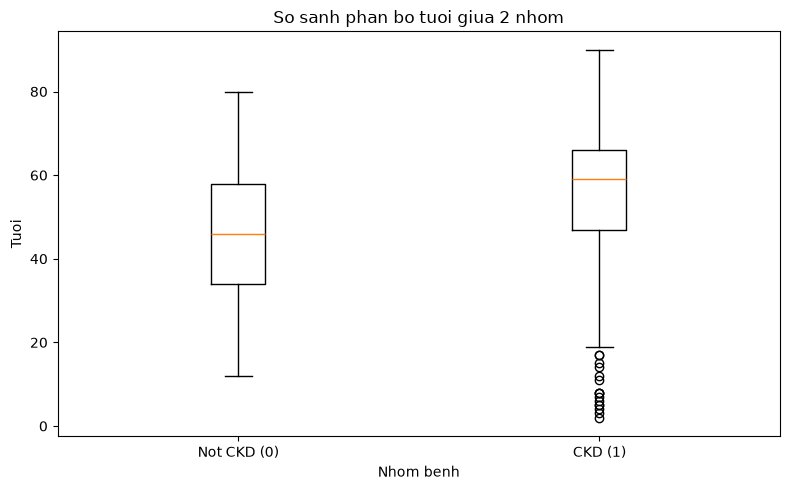

In [9]:

import matplotlib.pyplot as plt

# Lấy tuổi của hai nhóm
not_ckd = df[df["classification"] == 0]["age"].dropna()
ckd = df[df["classification"] == 1]["age"].dropna()

# Tạo biểu đồ
plt.figure(figsize=(8, 5))

plt.boxplot(
    [not_ckd, ckd],
    tick_labels=["Not CKD (0)", "CKD (1)"]
)

plt.title("So sanh phan bo tuoi giua 2 nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Tuoi")

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    folder / "age_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét tuổi theo lớp

Trung vị tuổi CKD là 59 so với 46 ở Not CKD; trung bình lần lượt 54,54 và 46,52.
Hai nhóm vẫn chồng lấp đáng kể, nên tuổi riêng lẻ không xác định nhãn bệnh.
Thống kê bỏ qua ô thiếu: còn 242 mẫu CKD và 149 mẫu Not CKD có tuổi.


In [10]:

# Thống kê Hemoglobin theo từng nhóm
hemo_stats = df.groupby("classification")["hemo"].agg([
    "count", "mean", "median", "min", "max", "std"
])

print("THONG KE HEMOGLOBIN THEO NHOM:")
display(hemo_stats.round(2))

# Kiểm tra số giá trị thiếu
print("So gia tri Hemoglobin bi thieu:")
print(df["hemo"].isna().sum())


THONG KE HEMOGLOBIN THEO NHOM:


,count,mean,median,min,max,std
classification,,,,,,
0,144,15.19,15.0,13.0,17.8,1.28
1,204,10.65,10.9,3.1,16.1,2.19


So gia tri Hemoglobin bi thieu:
52


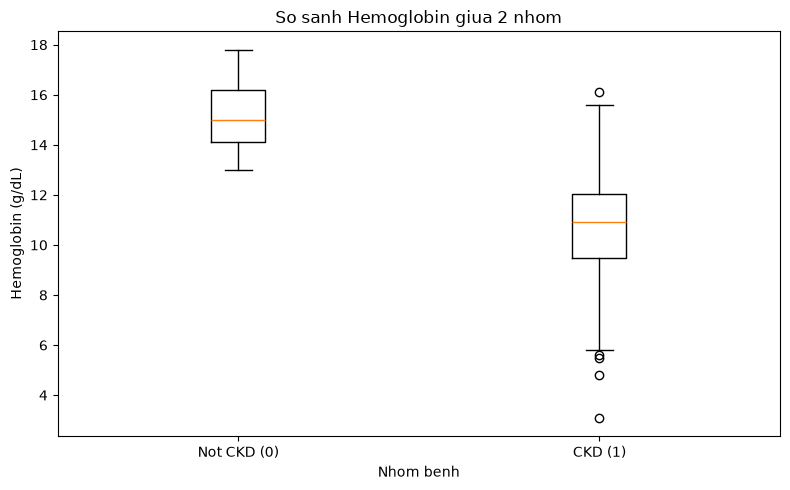

In [11]:

import matplotlib.pyplot as plt
from pathlib import Path

# Chia dữ liệu theo nhóm
not_ckd = df[df["classification"] == 0]["hemo"].dropna()
ckd = df[df["classification"] == 1]["hemo"].dropna()

# Tạo biểu đồ
plt.figure(figsize=(8, 5))

plt.boxplot(
    [not_ckd, ckd],
    tick_labels=["Not CKD (0)", "CKD (1)"]
)

plt.title("So sanh Hemoglobin giua 2 nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Hemoglobin (g/dL)")

plt.tight_layout()

# Xác định nơi lưu hình
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

# Lưu biểu đồ
plt.savefig(
    folder / "hemo_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét Hemoglobin

Trung vị `hemo` ở CKD là 10,9 so với 15,0 ở Not CKD; trung bình 10,65 so với 15,19.
Nhóm CKD có xu hướng giá trị thấp hơn, nhưng hai nhóm vẫn chồng lấp. Có 52 ô thiếu (13%).
Đây là liên hệ quan sát trong dataset, không chứng minh nhân quả hoặc tạo ra ngưỡng chẩn đoán.


In [12]:

# Thống kê Creatinine theo từng nhóm
sc_stats = df.groupby("classification")["sc"].agg([
    "count", "mean", "median", "min", "max", "std"
])

print("THONG KE CREATININE THEO NHOM:")
display(sc_stats.round(2))

# Kiểm tra giá trị thiếu
print("So gia tri Creatinine bi thieu:")
print(df["sc"].isna().sum())


THONG KE CREATININE THEO NHOM:


,count,mean,median,min,max,std
classification,,,,,,
0,145,0.87,0.90,0.4,1.2,0.26
1,238,4.41,2.25,0.5,76.0,6.95


So gia tri Creatinine bi thieu:
17


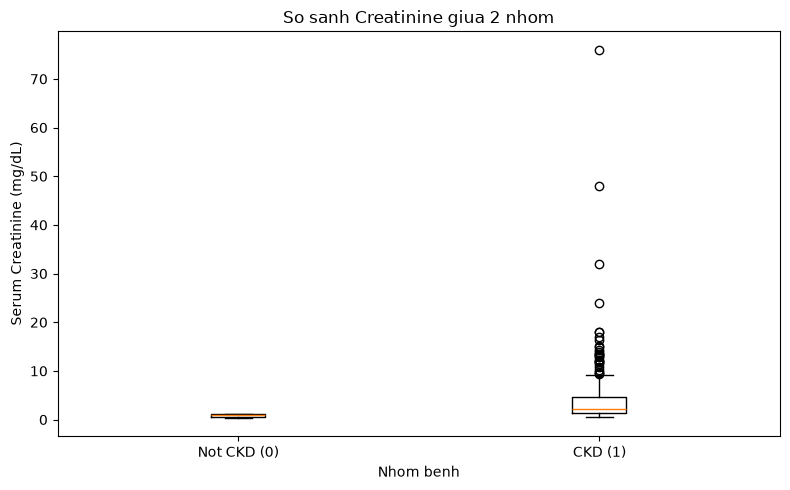

In [13]:

import matplotlib.pyplot as plt

# Chia dữ liệu theo nhóm
not_ckd = df[df["classification"] == 0]["sc"].dropna()
ckd = df[df["classification"] == 1]["sc"].dropna()

# Tạo biểu đồ
plt.figure(figsize=(8, 5))

plt.boxplot(
    [not_ckd, ckd],
    tick_labels=["Not CKD (0)", "CKD (1)"]
)

plt.title("So sanh Creatinine giua 2 nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Serum Creatinine (mg/dL)")

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    folder / "sc_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét Serum Creatinine

Trung vị `sc` ở CKD là 2,25 so với 0,90 ở Not CKD; trung bình 4,41 so với 0,87.
Giá trị lớn nhất ở CKD là 76, làm kéo giãn trục và tăng trung bình; cần đọc cả trung vị và boxplot.
Có 17 ô thiếu (4,25%). Không tự xóa điểm cực trị chỉ vì nó lớn; cần kiểm tra nguồn, đơn vị trước, mọi quyết định biến đổi cho mô hình phải đánh giá trên train.


In [14]:

# Thống kê huyết áp theo từng nhóm
bp_stats = df.groupby("classification")["bp"].agg([
    "count", "mean", "median", "min", "max", "std"
])

print("THONG KE HUYET AP THEO NHOM:")
display(bp_stats.round(2))

# Kiểm tra số giá trị thiếu
print("So gia tri huyet ap bi thieu:")
print(df["bp"].isna().sum())


THONG KE HUYET AP THEO NHOM:


,count,mean,median,min,max,std
classification,,,,,,
0,148,71.35,70.0,60.0,80.0,8.54
1,240,79.62,80.0,50.0,180.0,15.23


So gia tri huyet ap bi thieu:
12


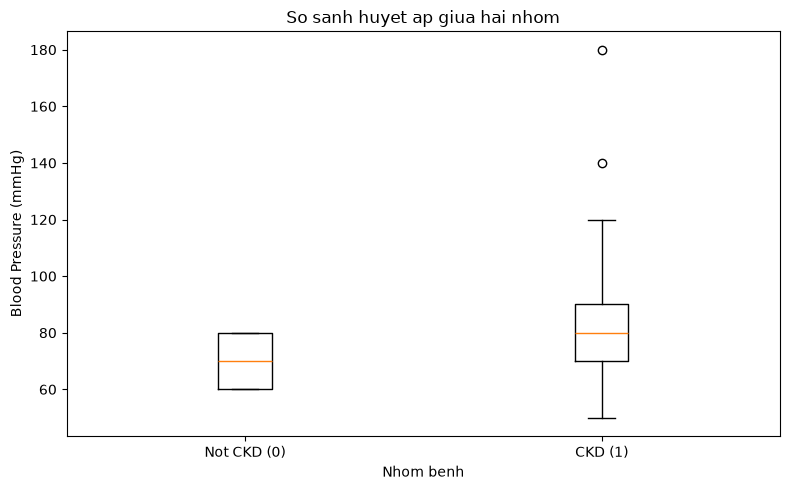

In [15]:

import matplotlib.pyplot as plt
from pathlib import Path

# Tách dữ liệu huyết áp thành hai nhóm
not_ckd = df.loc[df["classification"] == 0, "bp"].dropna()
ckd = df.loc[df["classification"] == 1, "bp"].dropna()

# Vẽ biểu đồ
plt.figure(figsize=(8, 5))

plt.boxplot(
    [not_ckd, ckd],
    tick_labels=["Not CKD (0)", "CKD (1)"]
)

plt.title("So sanh huyet ap giua hai nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Blood Pressure (mmHg)")

plt.tight_layout()

# Lưu biểu đồ
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "bp_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét huyết áp

Trung vị `bp` của CKD là 80 so với 70 ở Not CKD; trung bình 79,62 so với 71,35.
Nhóm CKD có độ phân tán lớn hơn và giá trị tối đa 180; hai nhóm vẫn có phần chồng lấp.
Có 12 ô thiếu (3%). `bp` là số đo huyết áp trong dữ liệu, khác với biến phân loại `htn`; không tự suy ngưỡng lâm sàng từ biểu đồ này.


In [16]:

# Chọn các thuộc tính số
cols = [
    "age", "bp", "bgr", "bu", "sc",
    "sod", "hemo", "pcv", "wc", "rc",
    "classification"
]

numeric_df = df[cols].astype(float)

# Tính ma trận tương quan Pearson
corr_matrix = numeric_df.corr()

print("MA TRAN TUONG QUAN:")
display(corr_matrix.round(2))

corr_matrix.to_csv(TABLES_DIR / "correlation.csv", encoding="utf-8-sig", index_label="column")


MA TRAN TUONG QUAN:


,age,bp,bgr,bu,sc,sod,hemo,pcv,wc,rc,classification
age,1.00,0.16,0.24,0.20,0.13,-0.10,-0.19,-0.24,0.12,-0.27,0.23
bp,0.16,1.00,0.16,0.19,0.15,-0.12,-0.31,-0.33,0.03,-0.26,0.29
bgr,0.24,0.16,1.00,0.14,0.11,-0.27,-0.31,-0.30,0.15,-0.28,0.42
bu,0.20,0.19,0.14,1.00,0.59,-0.32,-0.61,-0.61,0.05,-0.58,0.38
sc,0.13,0.15,0.11,0.59,1.00,-0.69,-0.40,-0.40,-0.01,-0.40,0.30
sod,-0.10,-0.12,-0.27,-0.32,-0.69,1.00,0.37,0.38,0.01,0.34,-0.38
hemo,-0.19,-0.31,-0.31,-0.61,-0.40,0.37,1.00,0.90,-0.17,0.80,-0.77
pcv,-0.24,-0.33,-0.30,-0.61,-0.40,0.38,0.90,1.00,-0.20,0.79,-0.74
wc,0.12,0.03,0.15,0.05,-0.01,0.01,-0.17,-0.20,1.00,-0.16,0.23
rc,-0.27,-0.26,-0.28,-0.58,-0.40,0.34,0.80,0.79,-0.16,1.00,-0.70


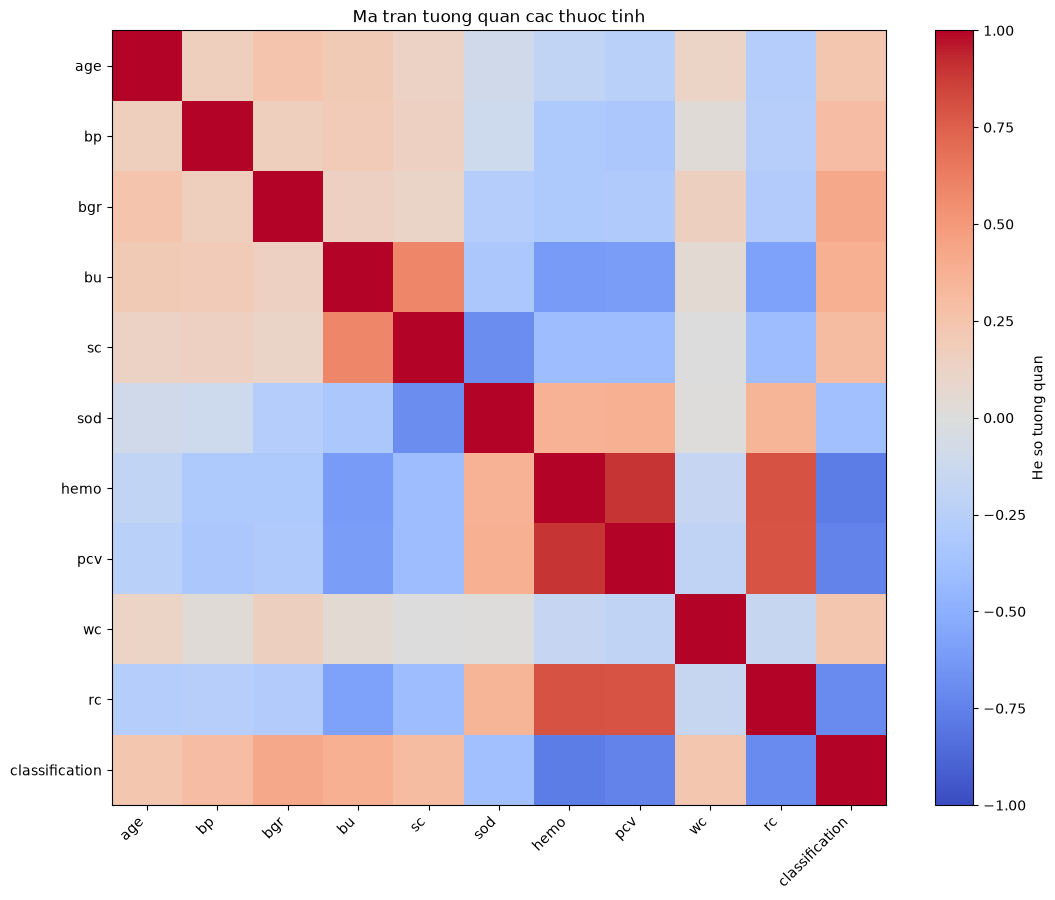

In [17]:

import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(11, 9))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="He so tuong quan")

plt.xticks(
    range(len(cols)),
    cols,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(cols)), cols)
plt.title("Ma tran tuong quan cac thuoc tinh")

plt.tight_layout()

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét ma trận tương quan

Kết quả phân tích tương quan Pearson cho thấy một số thuộc tính số có mối liên hệ đáng chú ý với nhãn bệnh thận mãn tính (CKD).

- **Hemoglobin (`hemo`)** có tương quan âm mạnh với CKD (r = -0.77).
- **Packed Cell Volume (`pcv`)** có tương quan âm mạnh với CKD (r = -0.74).
- **Red Blood Cell Count (`rc`)** có tương quan âm mạnh với CKD (r = -0.70).
- **Blood Glucose Random (`bgr`)** có tương quan dương với CKD (r = 0.42).

Ngoài ra, `hemo` và `pcv` có tương quan dương rất mạnh (r = 0.90), cho thấy hai thuộc tính có xu hướng biến thiên cùng nhau.

**Kết luận:** Trong các thuộc tính số được phân tích, `hemo`, `pcv` và `rc` có mối tương quan tuyến tính mạnh nhất với nhãn CKD. Tuy nhiên, tương quan không chứng minh quan hệ nhân quả và chưa đủ để quyết định lựa chọn đặc trưng cho mô hình.

In [18]:

# Xem các giá trị của cột htn
print("CAC GIA TRI CUA HTN:")
print(df["htn"].value_counts(dropna=False))

# Đếm số bệnh nhân theo hai nhóm
htn_table = pd.crosstab(
    df["classification"],
    df["htn"].fillna("Missing")
)

print("\nSO LUONG THEO NHOM:")
display(htn_table)

# Tính tỷ lệ phần trăm trong từng nhóm
htn_percent = pd.crosstab(
    df["classification"],
    df["htn"].fillna("Missing"),
    normalize="index"
) * 100

print("\nTY LE PHAN TRAM THEO NHOM:")
display(htn_percent.round(2))


CAC GIA TRI CUA HTN:
htn
no     251
yes    147
NaN      2
Name: count, dtype: int64

SO LUONG THEO NHOM:


htn,Missing,no,yes
classification,,,
0,2,148,0
1,0,103,147



TY LE PHAN TRAM THEO NHOM:


htn,Missing,no,yes
classification,,,
0,1.33,98.67,0.0
1,0.00,41.20,58.8


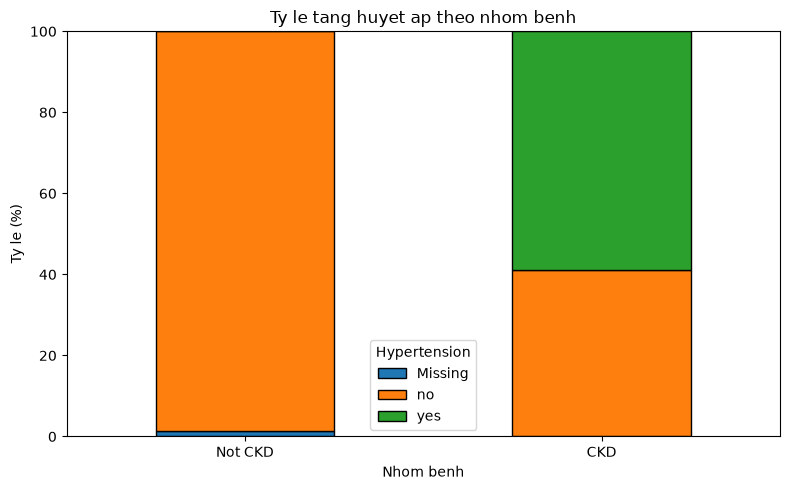

In [19]:

import matplotlib.pyplot as plt
from pathlib import Path

# Đổi tên nhóm để biểu đồ dễ đọc
htn_plot = htn_percent.rename(
    index={0: "Not CKD", 1: "CKD"}
)

# Vẽ biểu đồ cột chồng
ax = htn_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Ty le tang huyet ap theo nhom benh")
plt.xlabel("Nhom benh")
plt.ylabel("Ty le (%)")
plt.xticks(rotation=0)
plt.legend(title="Hypertension")
plt.tight_layout()

# Lưu biểu đồ
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "htn_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét thuộc tính tăng huyết áp (htn)

Kết quả cho thấy 58,8% bệnh nhân thuộc nhóm CKD có tăng huyết áp, trong khi nhóm Not CKD không ghi nhận trường hợp tăng huyết áp nào. Có 2 mẫu thiếu dữ liệu ở nhóm Not CKD (1,33%).

Điều này cho thấy thuộc tính `htn` có khả năng phân biệt hai nhóm trong dataset. Tuy nhiên, đây chỉ là mối liên hệ quan sát được, không đủ để khẳng định quan hệ nhân quả.

In [20]:

# Kiểm tra các giá trị của cột dm
print("CAC GIA TRI CUA DM:")
print(df["dm"].value_counts(dropna=False))

# Thống kê số lượng
dm_table = pd.crosstab(
    df["classification"],
    df["dm"].fillna("Missing")
)

print("\nSO LUONG THEO NHOM:")
display(dm_table)

# Tính tỷ lệ phần trăm
dm_percent = pd.crosstab(
    df["classification"],
    df["dm"].fillna("Missing"),
    normalize="index"
) * 100

print("\nTY LE PHAN TRAM:")
display(dm_percent.round(2))


CAC GIA TRI CUA DM:
dm
no     261
yes    137
NaN      2
Name: count, dtype: int64

SO LUONG THEO NHOM:


dm,Missing,no,yes
classification,,,
0,2,148,0
1,0,113,137



TY LE PHAN TRAM:


dm,Missing,no,yes
classification,,,
0,1.33,98.67,0.0
1,0.00,45.20,54.8


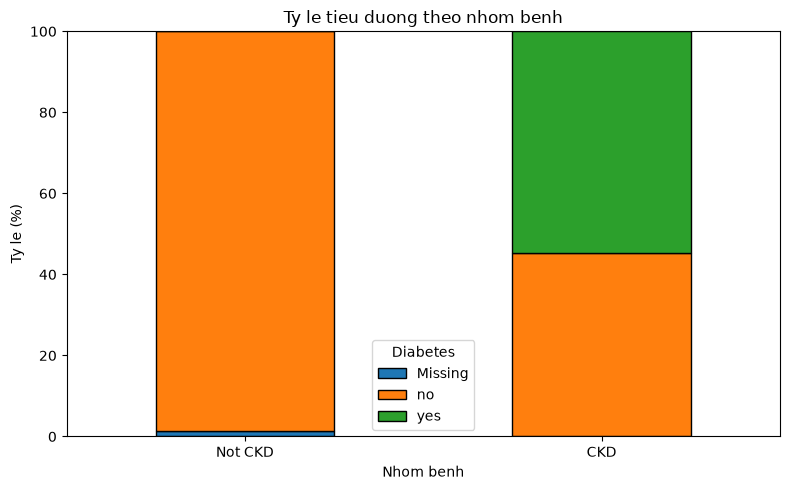

In [21]:

import matplotlib.pyplot as plt
from pathlib import Path

# Đổi tên hai nhóm
dm_plot = dm_percent.rename(
    index={0: "Not CKD", 1: "CKD"}
)

# Vẽ biểu đồ cột chồng theo tỷ lệ
ax = dm_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Ty le tieu duong theo nhom benh")
plt.xlabel("Nhom benh")
plt.ylabel("Ty le (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes")
plt.tight_layout()

# Xác định thư mục lưu biểu đồ
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

folder = root / "reports" / "figures"
folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    folder / "dm_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Nhận xét thuộc tính tiểu đường (dm)

Kết quả cho thấy 54,8% bệnh nhân thuộc nhóm CKD có tiểu đường, trong khi nhóm Not CKD không ghi nhận trường hợp nào. Có 2 mẫu thiếu dữ liệu, đều thuộc nhóm Not CKD.

Thuộc tính `dm` cho thấy sự khác biệt rõ rệt giữa hai nhóm trong dataset. Tuy nhiên, kết quả chỉ phản ánh mối liên hệ thống kê, không chứng minh quan hệ nhân quả.

rbc,Missing,abnormal,normal
classification,,,
0,9,0,141
1,143,47,60


rbc,Missing,abnormal,normal
classification,,,
0,6.0,0.0,94.0
1,57.2,18.8,24.0


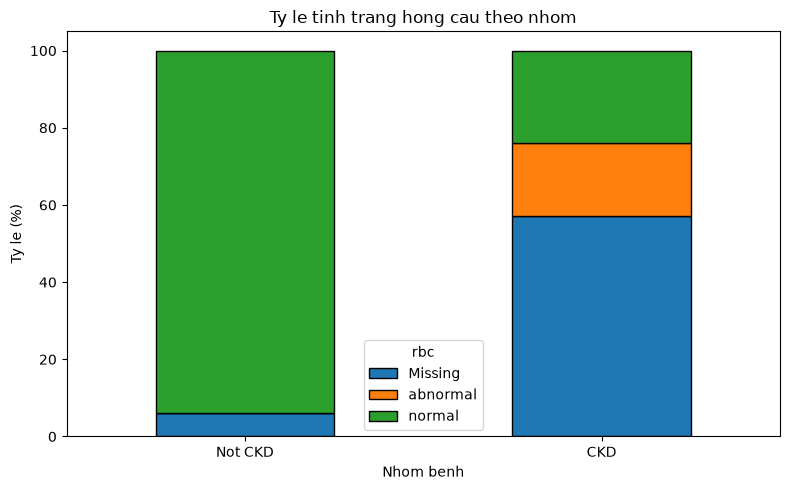

In [22]:
table = pd.crosstab(df[TARGET], df["rbc"].fillna("Missing"))
percent = pd.crosstab(df[TARGET], df["rbc"].fillna("Missing"), normalize="index") * 100
display(table)
display(percent.round(2))
table.to_csv(TABLES_DIR / "rbc_by_class_counts.csv", encoding="utf-8-sig")
percent.to_csv(TABLES_DIR / "rbc_by_class_percent.csv", encoding="utf-8-sig")
ax = percent.rename(index={0: "Not CKD", 1: "CKD"}).plot(kind="bar", stacked=True, figsize=(8, 5), edgecolor="black")
plt.title("Ty le tinh trang hong cau theo nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Ty le (%)")
plt.xticks(rotation=0)
plt.legend(title="rbc")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "rbc_by_class.png", dpi=300, bbox_inches="tight")
plt.show()


### Nhận xét tình trạng hồng cầu (`rbc`)

CKD có 18,8% `abnormal`, 24,0% `normal` và 57,2% thiếu; Not CKD có 94% `normal`, 6% thiếu và không ghi nhận `abnormal`.
Tỷ lệ tính trên toàn bộ mẫu của từng lớp, có giữ nhóm Missing; không nhầm 18,8% với tỷ lệ chỉ trên các mẫu đã biết `rbc`.
Mức thiếu khác nhau rõ giữa hai lớp, cần lưu ý nguy cơ mô hình học đặc điểm thu thập dữ liệu. `rbc` là tình trạng phân loại, khác `rc` là số lượng hồng cầu.


appet,Missing,good,poor
classification,,,
0,1,149,0
1,0,168,82


appet,Missing,good,poor
classification,,,
0,0.67,99.33,0.0
1,0.00,67.20,32.8


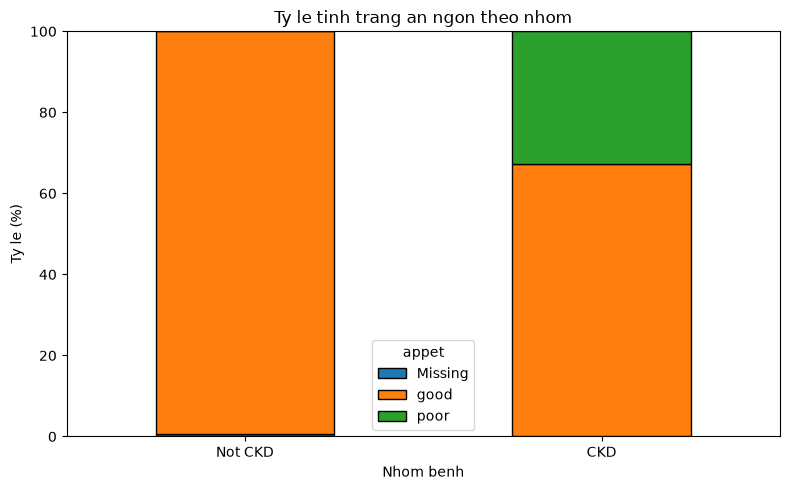

In [23]:
table = pd.crosstab(df[TARGET], df["appet"].fillna("Missing"))
percent = pd.crosstab(df[TARGET], df["appet"].fillna("Missing"), normalize="index") * 100
display(table)
display(percent.round(2))
table.to_csv(TABLES_DIR / "appet_by_class_counts.csv", encoding="utf-8-sig")
percent.to_csv(TABLES_DIR / "appet_by_class_percent.csv", encoding="utf-8-sig")
ax = percent.rename(index={0: "Not CKD", 1: "CKD"}).plot(kind="bar", stacked=True, figsize=(8, 5), edgecolor="black")
plt.title("Ty le tinh trang an ngon theo nhom")
plt.xlabel("Nhom benh")
plt.ylabel("Ty le (%)")
plt.xticks(rotation=0)
plt.legend(title="appet")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "appet_by_class.png", dpi=300, bbox_inches="tight")
plt.show()


### Nhận xét khẩu vị (`appet`)

CKD có 32,8% `poor`, 67,2% `good`; Not CKD có 99,33% `good` và 0,67% thiếu, không ghi nhận `poor`.
Biến này có khác biệt giữa hai nhóm trong mẫu hiện tại; không suy ra mọi người ăn kém đều mắc CKD.
Các quan sát trên toàn tập không được dùng để chọn đặc trưng qua tập test.


### Cách đọc tương quan và bàn giao

Pearson dùng các cặp giá trị không thiếu nên số mẫu có thể khác nhau giữa từng cặp; không mặc định mọi hệ số dùng đủ 400 mẫu.
Heatmap hiện là tập con 10 biến số và nhãn, không phải toàn bộ 24 thuộc tính; sg/al/su là mã phân loại nên không mặc định dùng tương quan tuyến tính.
Không xếp tương quan thành tầm quan trọng của mô hình. Chưa có đánh giá khả năng dự đoán trên test.

Bàn giao CSV gốc, `src/config.py`, `src/preprocess.py`, notebook này, hình và bảng trong `reports/`, cùng `reports/huong_dan_nguoi_1.md`.
Người 2 tách X/y rồi chia train/test phân tầng, chỉ fit imputer, encoder, scaler và mô hình trong Pipeline/CV trên train.
Đọc `reports/ban_giao_nguoi_2.md` để dùng API và xác nhận tích hợp. File gốc được giữ nguyên.
